In [11]:
import requests
import pandas as pd
from datetime import datetime, timezone

# Mandatory parameters
SYMBOL = "ETHUSDT"
#SYMBOL = "BTCUSDT"
endpoint = "https://api.binance.com/api/v3/klines"

# 22 Jun 00:00 UTC 
start = datetime(2026, 6, 22, tzinfo=timezone.utc)

# 22 Sep 00:00 UTC
end = datetime(2026, 9, 22, tzinfo=timezone.utc)

start_ms = int(start.timestamp() * 1000)
end_ms = int(end.timestamp() * 1000)

rows = []
cursor = start_ms

while cursor < end_ms:
    response = requests.get(
        endpoint,
        params={
            "symbol": SYMBOL,
            "interval": "1h",
            "startTime": cursor,
            "endTime": end_ms - 1,
            "limit": 1000,
        },
        timeout=30,
    )
    response.raise_for_status()
    batch = response.json()

    if not batch:
        break

    rows.extend(batch)
    cursor = int(batch[-1][0]) + 60 * 60 * 1000

    if len(batch) < 1000:
        break

columns = [
    "open_time", "open", "high", "low", "close", "volume",
    "close_time", "quote_volume", "trades",
    "taker_buy_volume", "taker_buy_quote_volume", "ignore",
]

bars = pd.DataFrame(rows, columns=columns)

if bars.empty:
    raise RuntimeError("Binance does not return any data")

bars["open_time"] = pd.to_datetime(bars["open_time"], unit="ms", utc=True)
bars["close_time"] = pd.to_datetime(bars["close_time"], unit="ms", utc=True)

numeric_columns = [
    "open", "high", "low", "close", "volume",
    "quote_volume", "taker_buy_volume", "taker_buy_quote_volume",
]

bars[numeric_columns] = bars[numeric_columns].astype(float)
bars = bars.drop_duplicates("open_time").sort_values("open_time").reset_index(drop=True)

print(f"Bars downloaded: {len(bars)}")
print(f"Period: {bars['open_time'].min()} — {bars['open_time'].max()}")

bars.head()

Bars downloaded: 2208
Period: 2026-06-22 00:00:00+00:00 — 2026-09-21 23:00:00+00:00


,open_time,open,high,low,close,volume,close_time,quote_volume,trades,taker_buy_volume,taker_buy_quote_volume,ignore
0,2026-06-22 00:00:00+00:00,1706.94,1732.20,1706.94,1726.95,10130.3805,2026-06-22 00:59:59.999000+00:00,1.743798e+07,200186,5895.5736,1.014728e+07,0
1,2026-06-22 01:00:00+00:00,1726.95,1759.84,1724.56,1743.82,22702.9713,2026-06-22 01:59:59.999000+00:00,3.958446e+07,298475,12263.5601,2.139398e+07,0
2,2026-06-22 02:00:00+00:00,1743.83,1745.28,1737.28,1737.28,6300.0591,2026-06-22 02:59:59.999000+00:00,1.096898e+07,124365,3122.3919,5.437247e+06,0
3,2026-06-22 03:00:00+00:00,1737.27,1740.98,1726.54,1730.00,9112.5799,2026-06-22 03:59:59.999000+00:00,1.579917e+07,136645,4405.1323,7.640979e+06,0
4,2026-06-22 04:00:00+00:00,1730.00,1735.96,1727.69,1735.31,6465.2801,2026-06-22 04:59:59.999000+00:00,1.120422e+07,85084,3711.0057,6.431177e+06,0


In [117]:
# Sort historical data
data = bars.sort_values("open_time").reset_index(drop=True).copy()

# Simulation starting point
TARGET_PRICE = 2300.0

# Find historical price closest to target
anchor_idx = (data["close"] - TARGET_PRICE).abs().idxmin()

anchor_time = data.loc[anchor_idx, "open_time"]
P0 = data.loc[anchor_idx, "close"]

# Historical hourly returns BEFORE the anchor
historical_returns = (
    data.loc[:anchor_idx, "close"]
    .pct_change()
    .dropna()
)

# Historical hourly volatility
VOLATILITY = historical_returns.std()

# Historical mean (for distribution analysis)
mu = historical_returns.mean()

print(f"Anchor time: {anchor_time}")
print(f"Starting price: {P0:.2f} USDT")
print(f"Historical mean: {mu:.4%}")
print(f"Historical hourly volatility: {VOLATILITY:.4%}")
print(f"Number of historical returns: {len(historical_returns)}")

Anchor time: 2026-08-20 11:00:00+00:00
Starting price: 2296.58 USDT
Historical mean: 0.0214%
Historical hourly volatility: 0.5396%
Number of historical returns: 1427


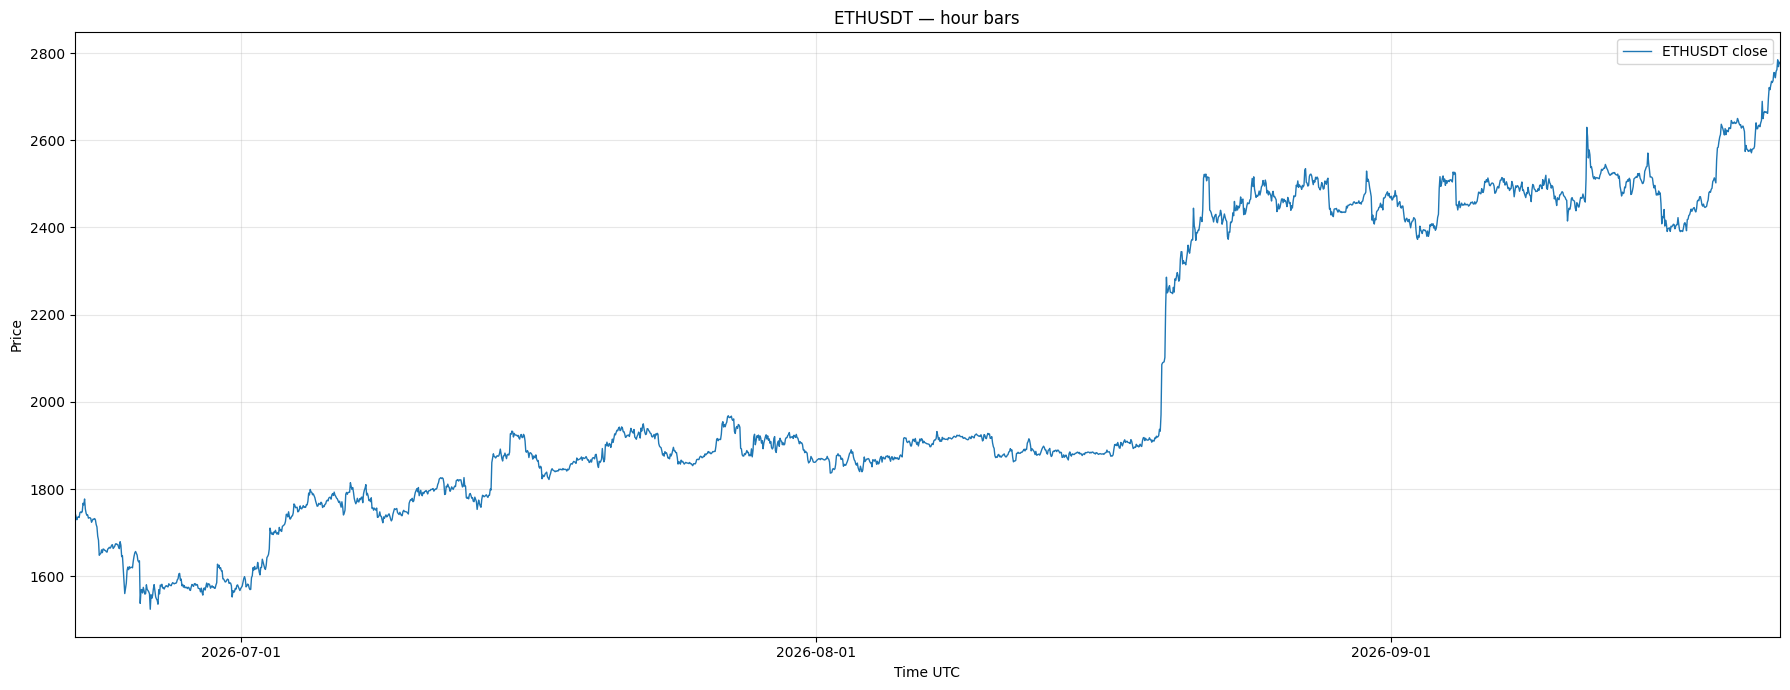

In [118]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

if "bars" not in globals() or bars.empty:
    raise RuntimeError("No bar data")

fig, ax = plt.subplots(figsize=(18, 7))

ax.plot(
    bars["open_time"],
    bars["close"],
    linewidth=1,
    label=f"{SYMBOL} close"
)

# Exact X-axis boundaries — no empty space
ax.set_xlim(
    bars["open_time"].min(),
    bars["open_time"].max()
)

ax.set_title(f"{SYMBOL} — hour bars")
ax.set_xlabel("Time UTC")
ax.set_ylabel("Price")
ax.grid(True, alpha=0.3)
ax.legend()

ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%Y-%m-%d", tz=bars["open_time"].dt.tz)
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Historical mean: 0.0214%
Historical volatility: 0.5396%

Sigma boundaries:
-1σ: -0.518%
+1σ: +0.561%
-2σ: -1.058%
+2σ: +1.101%
-3σ: -1.597%
+3σ: +1.640%

Historical extremes:
Minimum hourly return: -5.9701% (-11.10σ)
Maximum hourly return: +5.8475% (+10.80σ)


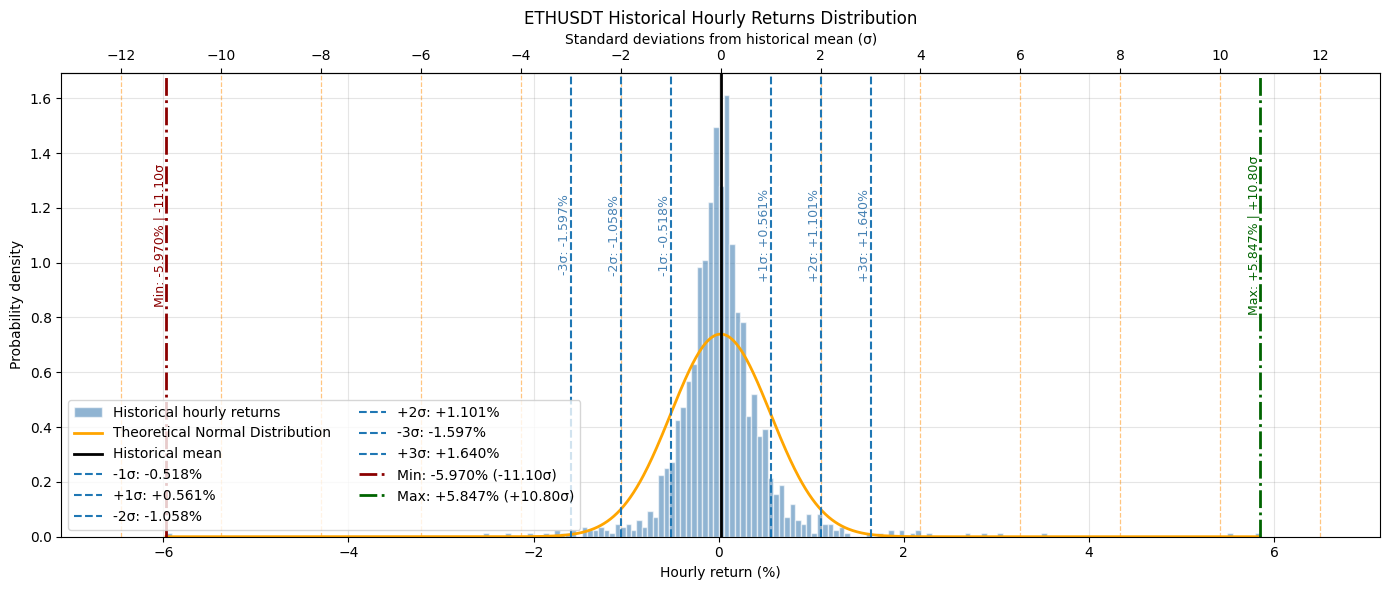

In [120]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

fig, ax = plt.subplots(figsize=(14, 6))

# Historical returns distribution
ax.hist(
    historical_returns * 100,
    bins=200,
    density=True,
    alpha=0.6,
    color="steelblue",
    edgecolor="white",
    label="Historical hourly returns"
)

# Theoretical Gaussian distribution
x = np.linspace(
    historical_returns.min() * 100,
    historical_returns.max() * 100,
    1000
)

normal_pdf = norm.pdf(
    x,
    loc=mu * 100,
    scale=sigma * 100
)

ax.plot(
    x,
    normal_pdf,
    color="orange",
    linewidth=2,
    label="Theoretical Normal Distribution"
)

# Historical mean
ax.axvline(
    mu * 100,
    color="black",
    linewidth=2,
    label="Historical mean"
)

# Sigma boundaries
for k in (1, 2, 3):
    lower = (mu - k * VOLATILITY) * 100
    upper = (mu + k * VOLATILITY) * 100

    ax.axvline(
        lower,
        linestyle="--",
        label=f"-{k}σ: {lower:+.3f}%"
    )

    ax.axvline(
        upper,
        linestyle="--",
        label=f"+{k}σ: {upper:+.3f}%"
    )

# Numeric labels for sigma boundaries
for k in (1, 2, 3):
    for sign in (-1, 1):
        value = (mu + sign * k * VOLATILITY) * 100

        ax.text(
            value,
            0.65,
            f"{sign*k:+d}σ: {value:+.3f}%",
            rotation=90,
            transform=ax.get_xaxis_transform(),
            ha="right",
            va="center",
            color="steelblue",
            fontsize=9
        )

# Historical extreme returns
rng = [
    (historical_returns.min() * 100, "Min", "darkred"),
    (historical_returns.max() * 100, "Max", "darkgreen")
]

for value, label, color in rng:
    z = (value / 100 - mu) / VOLATILITY

    ax.axvline(
        value,
        color=color,
        linewidth=2,
        linestyle="-.",
        label=f"{label}: {value:+.3f}% ({z:+.2f}σ)"
    )

    ax.text(
        value,
        0.65,
        f"{label}: {value:+.3f}% | {z:+.2f}σ",
        rotation=90,
        transform=ax.get_xaxis_transform(),
        ha="right",
        va="center",
        color=color,
        fontsize=9
    )

# Chart labels
ax.set(
    title=f"{SYMBOL} Historical Hourly Returns Distribution",
    xlabel="Hourly return (%)",
    ylabel="Probability density"
)

# ---------------------------------------------------
# Secondary horizontal axis — standard deviations
# ---------------------------------------------------

def percent_to_sigma(x):
    return (x / 100 - mu) / VOLATILITY

def sigma_to_percent(z):
    return (mu + z * VOLATILITY) * 100

ax_top = ax.secondary_xaxis(
    "top",
    functions=(percent_to_sigma, sigma_to_percent)
)

ax_top.set_xlabel(
    "Standard deviations from historical mean (σ)"
)

# Sigma ticks every 2 standard deviations
ax_top.set_xticks(np.arange(-12, 13, 2))

# ---------------------------------------------------
# Two independent grids
# ---------------------------------------------------

# Bottom axis grid — hourly returns (%)
ax.grid(
    True,
    axis="both",
    color="gray",
    linestyle="-",
    linewidth=0.8,
    alpha=0.20
)

# Sigma grid — drawn on the main axis
sigma_ticks = np.arange(-12, 13, 2)

for z in sigma_ticks:
    x_pos = sigma_to_percent(z)

    ax.axvline(
        x=x_pos,
        color="darkorange",
        linestyle="--",
        linewidth=0.9,
        alpha=0.5,
        zorder=0
    )

# Top axis tick positions
ax_top.set_xticks(sigma_ticks)

ax.set_axisbelow(True)

# ---------------------------------------------------
# Statistics
# ---------------------------------------------------

print(f"Historical mean: {mu:.4%}")
print(f"Historical volatility: {sigma:.4%}")

print("\nSigma boundaries:")
for k in (1, 2, 3):
    lower = (mu - k * VOLATILITY) * 100
    upper = (mu + k * VOLATILITY) * 100

    print(f"-{k}σ: {lower:+.3f}%")
    print(f"+{k}σ: {upper:+.3f}%")

# Historical extremes in sigma units
min_sigma = (historical_returns.min() - mu) / VOLATILITY
max_sigma = (historical_returns.max() - mu) / VOLATILITY

print("\nHistorical extremes:")
print(f"Minimum hourly return: {historical_returns.min():+.4%} ({min_sigma:+.2f}σ)")
print(f"Maximum hourly return: {historical_returns.max():+.4%} ({max_sigma:+.2f}σ)")

# ---------------------------------------------------
# Final plot
# ---------------------------------------------------

ax.legend(ncol=2)

plt.tight_layout()
plt.show()

Skewness: 1.1546
Excess kurtosis: 31.4775

Tail exceedance analysis:
2σ | Empirical: 4.1345% | Normal: 4.5500% | Ratio: 0.91x
3σ | Empirical: 1.7519% | Normal: 0.2700% | Ratio: 6.49x
4σ | Empirical: 0.7008% | Normal: 0.0063% | Ratio: 110.63x
5σ | Empirical: 0.4205% | Normal: 0.0001% | Ratio: 7334.03x


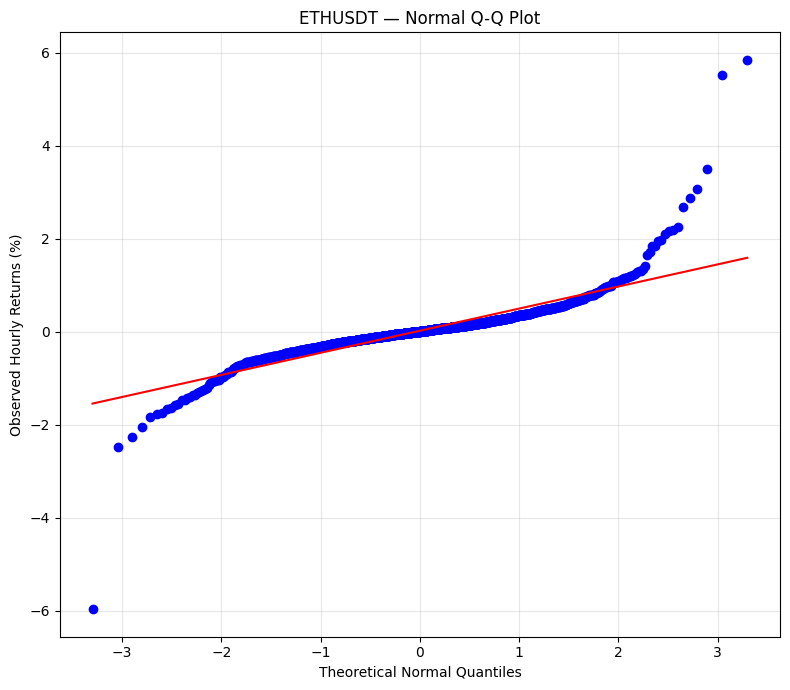

In [121]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import kurtosis, skew, norm
from scipy import stats

# Historical returns from the first cell
returns = historical_returns.dropna()

# Distribution statistics
excess_kurtosis = kurtosis(returns, fisher=True, bias=False)
skewness = skew(returns, bias=False)

print(f"Skewness: {skewness:.4f}")
print(f"Excess kurtosis: {excess_kurtosis:.4f}")

print("\nTail exceedance analysis:")

for k in (2, 3, 4, 5):
    # Empirical two-sided exceedance probability
    empirical = np.mean(
        np.abs(returns - mu) > k * VOLATILITY
    )

    # Expected probability under normality
    theoretical = 2 * norm.sf(k)

    ratio = empirical / theoretical

    print(
        f"{k}σ | "
        f"Empirical: {empirical:.4%} | "
        f"Normal: {theoretical:.4%} | "
        f"Ratio: {ratio:.2f}x"
    )

# ---------------------------------------------------
# Normal Q-Q Plot
# ---------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 7))

stats.probplot(
    returns * 100,
    dist="norm",
    plot=ax
)

ax.set_title(f"{SYMBOL} — Normal Q-Q Plot")
ax.set_xlabel("Theoretical Normal Quantiles")
ax.set_ylabel("Observed Hourly Returns (%)")

ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Starting price: 2296.58 USDT
Historical hourly volatility: 0.5396%
Number of paths: 10000
Simulation horizon: 1000 hours


/tmp/ipykernel_27576/1687898904.py:75: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
/home/greed/miniconda3/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


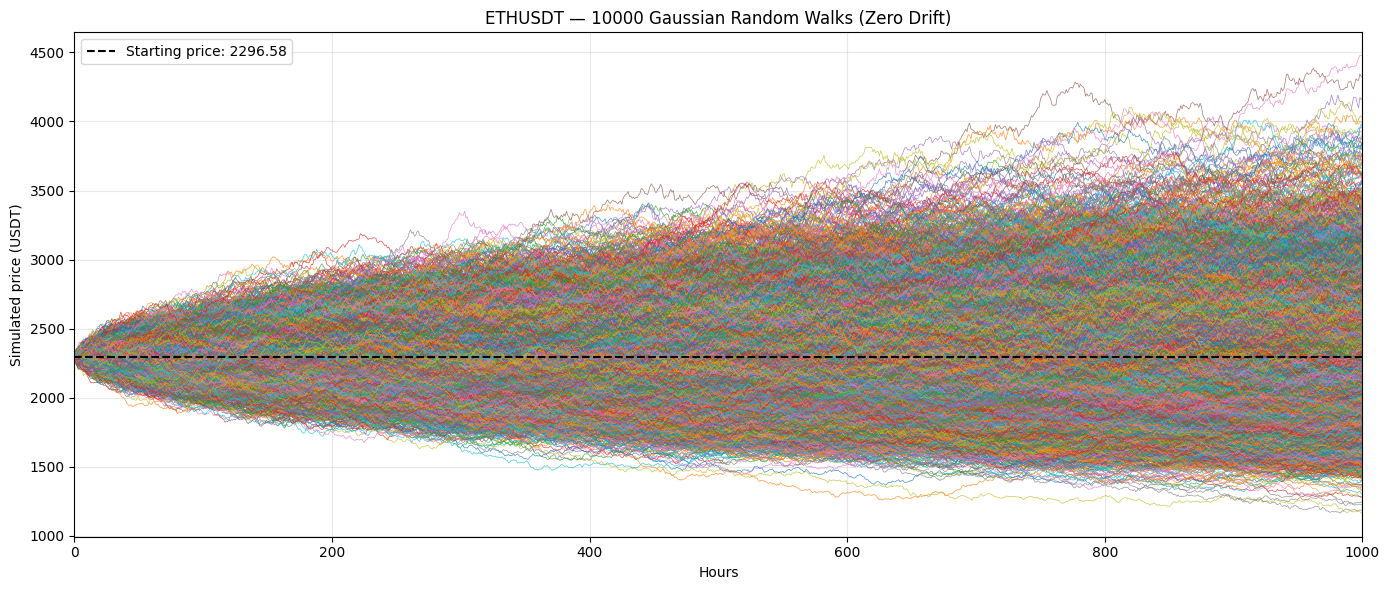

In [133]:
import numpy as np
import matplotlib.pyplot as plt

# Random Walk without drift
def get_one_path(volatility, P0, N, seed):
    rnd = np.random.default_rng(seed)

    returns = rnd.normal(
        loc=0,
        scale=volatility,
        size=N
    )

    price_path = P0 * np.cumprod(
        np.r_[1, 1 + returns]
    )

    return price_path


# Simulation parameters
experiments_count = 10000
number_of_steps_in_price_path = 1000

# Generate random paths
prices = []

for i in range(experiments_count):
    one_path = get_one_path(
        volatility=VOLATILITY,
        P0=P0,
        N=number_of_steps_in_price_path,
        seed=22 + i
    )

    prices.append(one_path)

prices = np.array(prices)

# Simulation parameters
print(f"Starting price: {P0:.2f} USDT")
print(f"Historical hourly volatility: {VOLATILITY:.4%}")
print(f"Number of paths: {len(prices)}")
print(f"Simulation horizon: {number_of_steps_in_price_path} hours")

# Plot
fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    prices.T,
    alpha=0.8,
    linewidth=0.5
)

ax.axhline(
    P0,
    color="black",
    linestyle="--",
    label=f"Starting price: {P0:.2f}"
)

ax.set_title(
    f"{SYMBOL} — {experiments_count} Gaussian Random Walks (Zero Drift)"
)

ax.set_xlabel("Hours")
ax.set_ylabel("Simulated price (USDT)")

# Remove horizontal padding
ax.set_xlim(0, number_of_steps_in_price_path)

ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

In [134]:
# Barrier parameters
BARRIER_PRICE = 3000

# Check whether each path crossed the barrier
crossed = (prices >= BARRIER_PRICE).any(axis=1)

crossed_count = crossed.sum()
crossed_probability = crossed.mean()

print(f"Total paths: {len(prices)}")
print(f"Crossed barrier: {crossed_count}")
print(f"Did not cross: {len(prices) - crossed_count}")
print(f"Barrier crossing probability: {crossed_probability:.2%}")

Total paths: 10000
Crossed barrier: 948
Did not cross: 9052
Barrier crossing probability: 9.48%


Total paths: 10000
Crossed barrier: 948
Did not cross: 9052
Barrier crossing probability: 9.48%


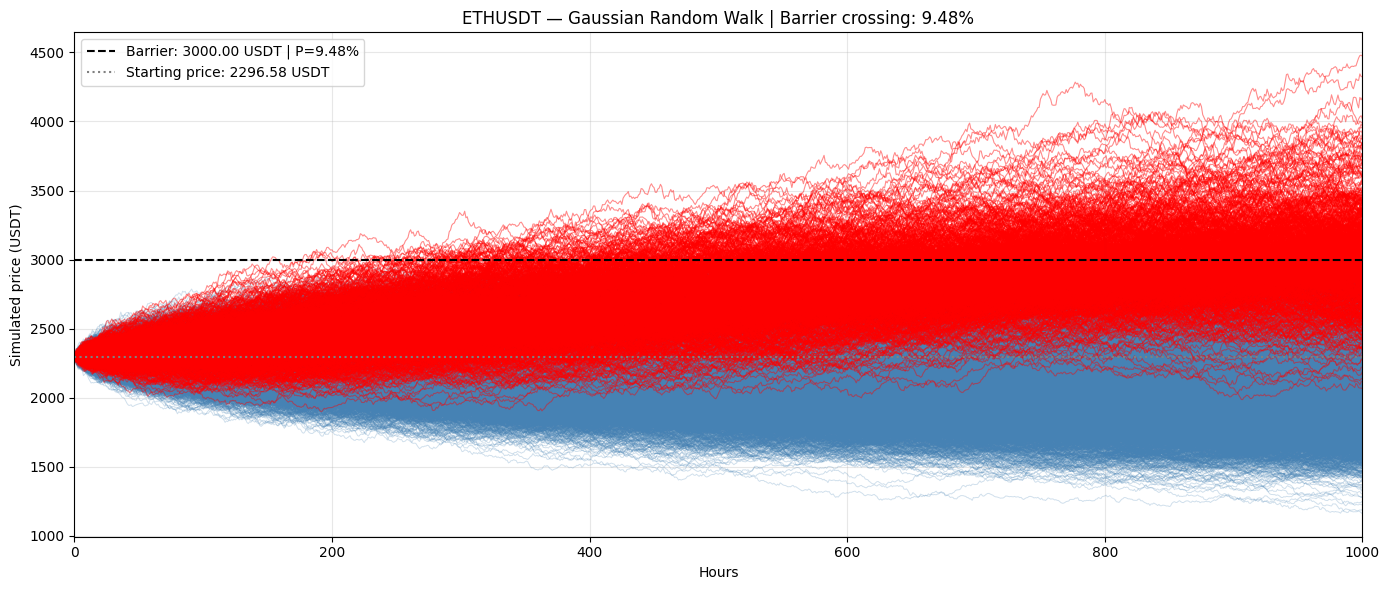

In [135]:
import matplotlib.pyplot as plt

# Barrier parameters
BARRIER_PRICE = 3000.0

# Detect barrier crossings
crossed = (prices >= BARRIER_PRICE).any(axis=1)

crossed_count = crossed.sum()
crossed_probability = crossed.mean()

print(f"Total paths: {len(prices)}")
print(f"Crossed barrier: {crossed_count}")
print(f"Did not cross: {len(prices) - crossed_count}")
print(f"Barrier crossing probability: {crossed_probability:.2%}")

# Plot
fig, ax = plt.subplots(figsize=(14, 6))

# Paths that did not cross
ax.plot(
    prices[~crossed].T,
    color="steelblue",
    alpha=0.25,
    linewidth=0.7
)

# Paths that crossed the barrier
ax.plot(
    prices[crossed].T,
    color="red",
    alpha=0.45,
    linewidth=0.8
)

# Barrier
ax.axhline(
    BARRIER_PRICE,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label=f"Barrier: {BARRIER_PRICE:.2f} USDT | P={crossed_probability:.2%}"
)

# Starting price
ax.axhline(
    P0,
    color="gray",
    linestyle=":",
    linewidth=1.5,
    label=f"Starting price: {P0:.2f} USDT"
)

ax.set_title(
    f"{SYMBOL} — Gaussian Random Walk | "
    f"Barrier crossing: {crossed_probability:.2%}"
)

ax.set_xlabel("Hours")
ax.set_ylabel("Simulated price (USDT)")

# Remove horizontal padding
ax.set_xlim(0, prices.shape[1] - 1)

ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

Anchor time: 2026-08-20 11:00:00+00:00
Starting price: 2296.58 USDT
Historical hourly volatility: 0.5396%
Simulation horizon: 780 hours
Number of simulated paths: 100


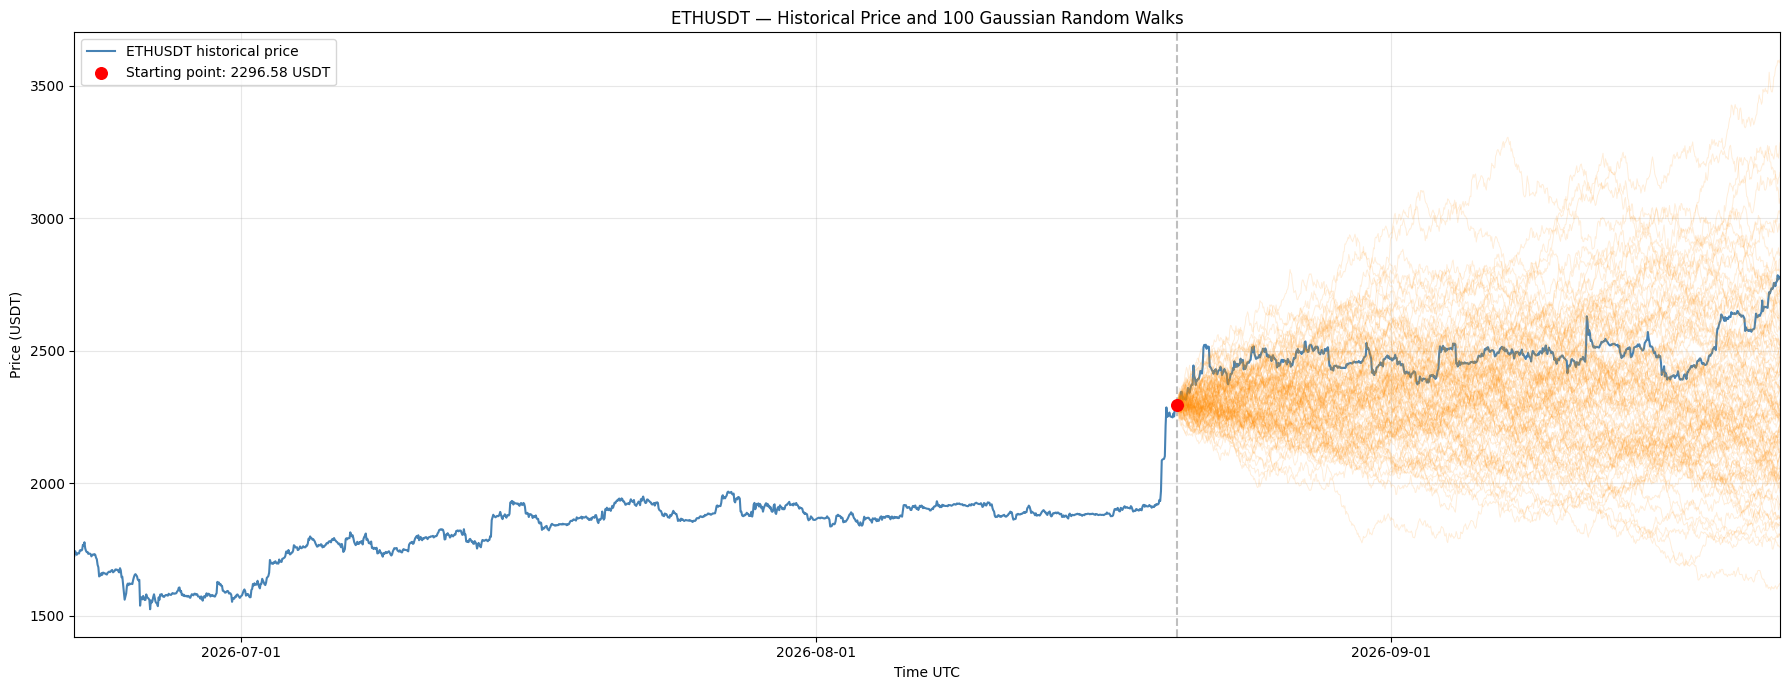

In [143]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# ---------------------------------------------------
# Simulation parameters
# ---------------------------------------------------

experiments_count = 100

# Number of hours from anchor to end of historical data
number_of_steps_in_price_path = len(data) - anchor_idx - 1

# ---------------------------------------------------
# Generate Random Walks using existing VOLATILITY
# ---------------------------------------------------

prices = []

for i in range(experiments_count):
    one_path = get_one_path(
        volatility=VOLATILITY,
        P0=P0,
        N=number_of_steps_in_price_path,
        seed=22 + i
    )

    prices.append(one_path)

prices = np.array(prices)

# Future hourly timestamps
simulation_times = data.loc[
    anchor_idx:, "open_time"
].reset_index(drop=True)

# ---------------------------------------------------
# Simulation information
# ---------------------------------------------------

print(f"Anchor time: {anchor_time}")
print(f"Starting price: {P0:.2f} USDT")
print(f"Historical hourly volatility: {VOLATILITY:.4%}")
print(f"Simulation horizon: {number_of_steps_in_price_path} hours")
print(f"Number of simulated paths: {len(prices)}")

# ---------------------------------------------------
# Plot
# ---------------------------------------------------

fig, ax = plt.subplots(figsize=(18, 7))

# Historical price
ax.plot(
    data["open_time"],
    data["close"],
    color="steelblue",
    linewidth=1.5,
    label=f"{SYMBOL} historical price"
)

# Random paths
ax.plot(
    simulation_times,
    prices.T,
    color="darkorange",
    alpha=0.15,
    linewidth=0.7
)

# Anchor point
ax.scatter(
    anchor_time,
    P0,
    color="red",
    s=70,
    zorder=5,
    label=f"Starting point: {P0:.2f} USDT"
)

ax.axvline(
    anchor_time,
    color="gray",
    linestyle="--",
    alpha=0.5
)

# ---------------------------------------------------
# Chart formatting
# ---------------------------------------------------

ax.set_title(
    f"{SYMBOL} — Historical Price and "
    f"{experiments_count} Gaussian Random Walks"
)

ax.set_xlabel("Time UTC")
ax.set_ylabel("Price (USDT)")

# Exact historical boundaries
ax.set_xlim(
    data["open_time"].min(),
    data["open_time"].max()
)

ax.xaxis.set_major_locator(mdates.MonthLocator())

ax.xaxis.set_major_formatter(
    mdates.DateFormatter(
        "%Y-%m-%d",
        tz=data["open_time"].dt.tz
    )
)

ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

Total paths: 100
Take Profit price: 2755.90 USDT
Stop Loss price: 1837.26 USDT

TP crossing probability: 24.00%
SL crossing probability: 8.00%
Both barriers: 0.00%
Neither barrier: 68.00%

Path categories:
Positive only: 24 (24.00%)
Negative only: 8 (8.00%)
Both: 0 (0.00%)
Neutral: 68 (68.00%)


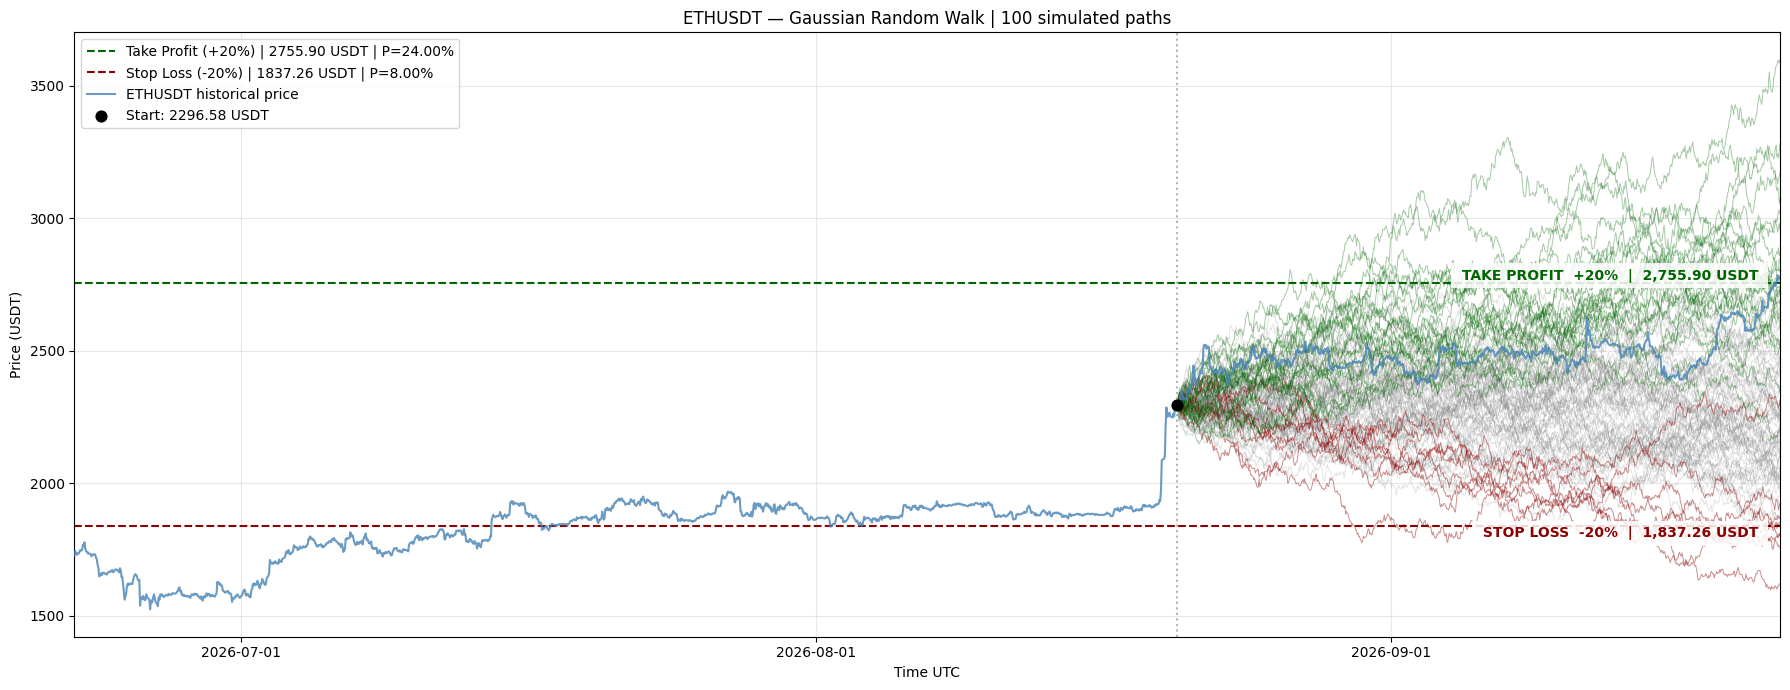

In [144]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# ---------------------------------------------------
# Barriers
# ---------------------------------------------------

TP_PRICE = P0 * 1.20  # +20%
SL_PRICE = P0 * 0.80  # -20%

# Detect crossings
tp_crossed = (prices >= TP_PRICE).any(axis=1)
sl_crossed = (prices <= SL_PRICE).any(axis=1)

# Four mutually exclusive categories
positive = tp_crossed & ~sl_crossed
negative = sl_crossed & ~tp_crossed
both = tp_crossed & sl_crossed
neutral = ~tp_crossed & ~sl_crossed

# Probabilities
tp_prob = tp_crossed.mean()
sl_prob = sl_crossed.mean()
both_prob = both.mean()
neutral_prob = neutral.mean()

# ---------------------------------------------------
# Statistics
# ---------------------------------------------------

print(f"Total paths: {len(prices)}")
print(f"Take Profit price: {TP_PRICE:.2f} USDT")
print(f"Stop Loss price: {SL_PRICE:.2f} USDT")

print(f"\nTP crossing probability: {tp_prob:.2%}")
print(f"SL crossing probability: {sl_prob:.2%}")
print(f"Both barriers: {both_prob:.2%}")
print(f"Neither barrier: {neutral_prob:.2%}")

print("\nPath categories:")
print(f"Positive only: {positive.sum()} ({positive.mean():.2%})")
print(f"Negative only: {negative.sum()} ({negative.mean():.2%})")
print(f"Both: {both.sum()} ({both_prob:.2%})")
print(f"Neutral: {neutral.sum()} ({neutral_prob:.2%})")

# ---------------------------------------------------
# Plot
# ---------------------------------------------------

fig, ax = plt.subplots(figsize=(18, 7))

# Neutral paths
ax.plot(
    simulation_times,
    prices[neutral].T,
    color="gray",
    alpha=0.25,
    linewidth=0.6
)

# Negative paths — SL only
ax.plot(
    simulation_times,
    prices[negative].T,
    color="darkred",
    alpha=0.45,
    linewidth=0.7
)

# Positive paths — TP only
ax.plot(
    simulation_times,
    prices[positive].T,
    color="darkgreen",
    alpha=0.35,
    linewidth=0.7
)

# Paths that crossed BOTH barriers
ax.plot(
    simulation_times,
    prices[both].T,
    color="darkorange",
    alpha=0.5,
    linewidth=0.8
)

# Take Profit barrier
ax.axhline(
    TP_PRICE,
    color="darkgreen",
    linestyle="--",
    linewidth=1.5,
    label=f"Take Profit (+20%) | {TP_PRICE:.2f} USDT | P={tp_prob:.2%}"
)

# Stop Loss barrier
ax.axhline(
    SL_PRICE,
    color="darkred",
    linestyle="--",
    linewidth=1.5,
    label=f"Stop Loss (-20%) | {SL_PRICE:.2f} USDT | P={sl_prob:.2%}"
)

# Labels directly on barrier lines
ax.text(
    0.99,
    TP_PRICE,
    f" TAKE PROFIT  +20%  |  {TP_PRICE:,.2f} USDT ",
    transform=ax.get_yaxis_transform(),
    color="darkgreen",
    fontsize=10,
    fontweight="bold",
    ha="right",
    va="bottom",
    bbox=dict(facecolor="white", alpha=0.85, edgecolor="none")
)

ax.text(
    0.99,
    SL_PRICE,
    f" STOP LOSS  -20%  |  {SL_PRICE:,.2f} USDT ",
    transform=ax.get_yaxis_transform(),
    color="darkred",
    fontsize=10,
    fontweight="bold",
    ha="right",
    va="top",
    bbox=dict(facecolor="white", alpha=0.85, edgecolor="none")
)

# Historical ETH price
ax.plot(
    data["open_time"],
    data["close"],
    color="steelblue",
    alpha=0.8,
    linewidth=1.5,
    label=f"{SYMBOL} historical price",
    zorder=3
)

# Starting point
ax.scatter(
    anchor_time,
    P0,
    color="black",
    s=60,
    zorder=5,
    label=f"Start: {P0:.2f} USDT"
)

# Anchor time
ax.axvline(
    anchor_time,
    color="gray",
    linestyle=":",
    alpha=0.6
)

# ---------------------------------------------------
# Chart formatting
# ---------------------------------------------------

ax.set_title(
    f"{SYMBOL} — Gaussian Random Walk | "
    f"{len(prices)} simulated paths"
)

ax.set_xlabel("Time UTC")
ax.set_ylabel("Price (USDT)")

# Exact historical boundaries
ax.set_xlim(
    data["open_time"].min(),
    data["open_time"].max()
)

ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(
    mdates.DateFormatter(
        "%Y-%m-%d",
        tz=data["open_time"].dt.tz
    )
)

ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

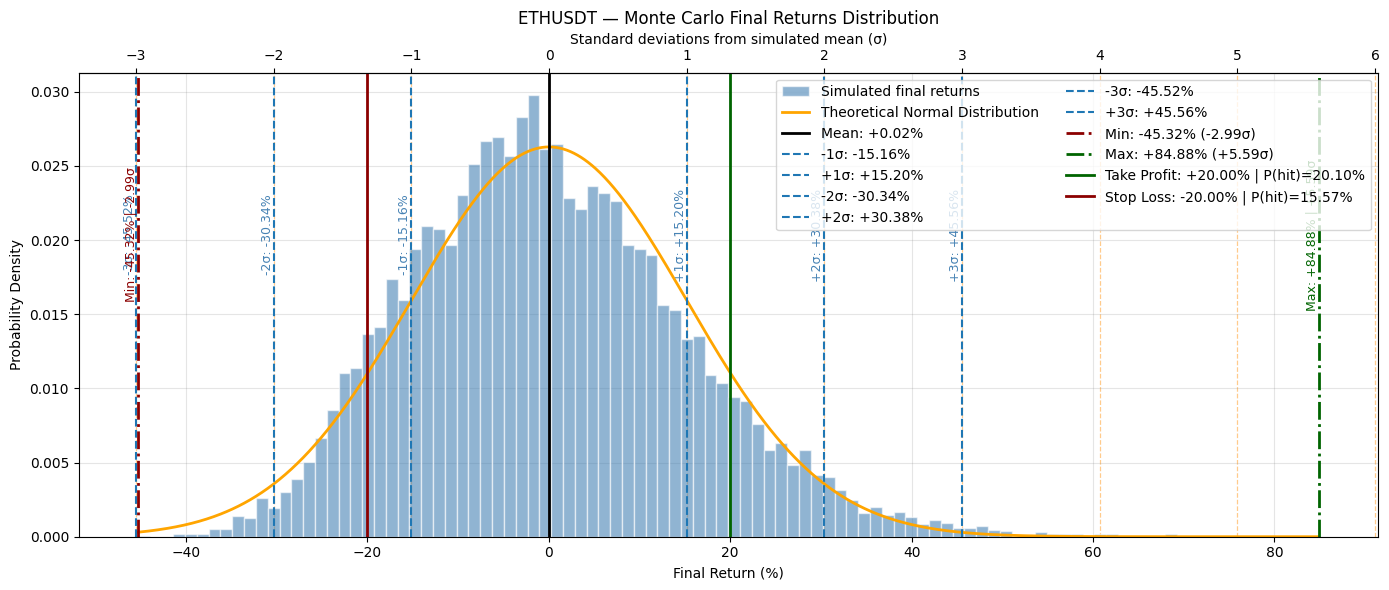

Total simulations: 10000
Historical hourly volatility: 0.5396%
Simulation horizon: 780 hours

Simulated mean final return: +0.0209%
Simulated final return volatility: 15.1804%

Sigma boundaries:
-1σ: -15.160%
+1σ: +15.201%
-2σ: -30.340%
+2σ: +30.382%
-3σ: -45.520%
+3σ: +45.562%

Simulated extremes:
Minimum final return: -45.3194% (-2.99σ)
Maximum final return: +84.8814% (+5.59σ)

Barrier crossing probabilities:
Take Profit (+20%): 20.10%
Stop Loss (-20%): 15.57%
Both barriers: 0.01%
Neither barrier: 64.34%

Final outcome probabilities:
Finished above +20%: 10.00%
Finished below -20%: 8.37%
Finished between barriers: 81.63%


In [139]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# ---------------------------------------------------
# Final returns of simulated price paths (%)
# ---------------------------------------------------

final_prices = prices[:, -1]
final_returns = (final_prices / P0 - 1) * 100

# Distribution statistics of final returns
mu_sim = final_returns.mean()
sigma_sim = final_returns.std(ddof=1)

# Barrier returns (%)
tp_return = (TP_PRICE / P0 - 1) * 100
sl_return = (SL_PRICE / P0 - 1) * 100

# ---------------------------------------------------
# Plot
# ---------------------------------------------------

fig, ax = plt.subplots(figsize=(14, 6))

# Simulated final returns distribution
ax.hist(
    final_returns,
    bins=100,
    density=True,
    alpha=0.6,
    color="steelblue",
    edgecolor="white",
    label="Simulated final returns"
)

# Theoretical Gaussian distribution
x = np.linspace(
    final_returns.min(),
    final_returns.max(),
    1000
)

normal_pdf = norm.pdf(
    x,
    loc=mu_sim,
    scale=sigma_sim
)

ax.plot(
    x,
    normal_pdf,
    color="orange",
    linewidth=2,
    label="Theoretical Normal Distribution"
)

# Simulated mean
ax.axvline(
    mu_sim,
    color="black",
    linewidth=2,
    label=f"Mean: {mu_sim:+.2f}%"
)

# ---------------------------------------------------
# Sigma boundaries
# ---------------------------------------------------

for k in (1, 2, 3):
    lower = mu_sim - k * sigma_sim
    upper = mu_sim + k * sigma_sim

    ax.axvline(
        lower,
        linestyle="--",
        label=f"-{k}σ: {lower:+.2f}%"
    )

    ax.axvline(
        upper,
        linestyle="--",
        label=f"+{k}σ: {upper:+.2f}%"
    )

    # Numeric labels
    for value, sign in [(lower, -1), (upper, 1)]:
        ax.text(
            value,
            0.65,
            f"{sign*k:+d}σ: {value:+.2f}%",
            rotation=90,
            transform=ax.get_xaxis_transform(),
            ha="right",
            va="center",
            color="steelblue",
            fontsize=9
        )

# ---------------------------------------------------
# Simulated extremes
# ---------------------------------------------------

extremes = [
    (final_returns.min(), "Min", "darkred"),
    (final_returns.max(), "Max", "darkgreen")
]

for value, label, color in extremes:
    z = (value - mu_sim) / sigma_sim

    ax.axvline(
        value,
        color=color,
        linewidth=2,
        linestyle="-.",
        label=f"{label}: {value:+.2f}% ({z:+.2f}σ)"
    )

    ax.text(
        value,
        0.65,
        f"{label}: {value:+.2f}% | {z:+.2f}σ",
        rotation=90,
        transform=ax.get_xaxis_transform(),
        ha="right",
        va="center",
        color=color,
        fontsize=9
    )

# ---------------------------------------------------
# Take Profit / Stop Loss barriers
# ---------------------------------------------------

ax.axvline(
    tp_return,
    color="darkgreen",
    linewidth=2,
    label=f"Take Profit: +{tp_return:.2f}% | P(hit)={tp_prob:.2%}"
)

ax.axvline(
    sl_return,
    color="darkred",
    linewidth=2,
    label=f"Stop Loss: {sl_return:.2f}% | P(hit)={sl_prob:.2%}"
)

# ---------------------------------------------------
# Secondary horizontal axis — standard deviations
# ---------------------------------------------------

def return_to_sigma(x):
    return (x - mu_sim) / sigma_sim

def sigma_to_return(z):
    return mu_sim + z * sigma_sim

ax_top = ax.secondary_xaxis(
    "top",
    functions=(return_to_sigma, sigma_to_return)
)

ax_top.set_xlabel(
    "Standard deviations from simulated mean (σ)"
)

# ---------------------------------------------------
# Two independent grids
# ---------------------------------------------------

# Bottom axis grid — final returns (%)
ax.grid(
    True,
    axis="both",
    color="gray",
    linestyle="-",
    linewidth=0.8,
    alpha=0.20
)

# Sigma ticks adapted to simulated range
sigma_min = return_to_sigma(final_returns.min())
sigma_max = return_to_sigma(final_returns.max())

sigma_ticks = np.arange(
    np.floor(sigma_min),
    np.ceil(sigma_max) + 1,
    1
)

# Sigma grid on the main axis
for z in sigma_ticks:
    x_pos = sigma_to_return(z)

    ax.axvline(
        x=x_pos,
        color="darkorange",
        linestyle="--",
        linewidth=0.9,
        alpha=0.45,
        zorder=0
    )

ax_top.set_xticks(sigma_ticks)

ax.set_axisbelow(True)

# ---------------------------------------------------
# Chart formatting
# ---------------------------------------------------

ax.set(
    title=f"{SYMBOL} — Monte Carlo Final Returns Distribution",
    xlabel="Final Return (%)",
    ylabel="Probability Density"
)

ax.legend(ncol=2)

plt.tight_layout()
plt.show()

# ---------------------------------------------------
# Statistics
# ---------------------------------------------------

print(f"Total simulations: {len(prices)}")
print(f"Historical hourly volatility: {VOLATILITY:.4%}")
print(f"Simulation horizon: {number_of_steps_in_price_path} hours")

print(f"\nSimulated mean final return: {mu_sim:+.4f}%")
print(f"Simulated final return volatility: {sigma_sim:.4f}%")

print("\nSigma boundaries:")
for k in (1, 2, 3):
    print(f"-{k}σ: {mu_sim - k * sigma_sim:+.3f}%")
    print(f"+{k}σ: {mu_sim + k * sigma_sim:+.3f}%")

print("\nSimulated extremes:")
print(
    f"Minimum final return: {final_returns.min():+.4f}% "
    f"({sigma_min:+.2f}σ)"
)
print(
    f"Maximum final return: {final_returns.max():+.4f}% "
    f"({sigma_max:+.2f}σ)"
)

# ---------------------------------------------------
# Barrier crossing probabilities
# ---------------------------------------------------

print("\nBarrier crossing probabilities:")
print(f"Take Profit (+20%): {tp_prob:.2%}")
print(f"Stop Loss (-20%): {sl_prob:.2%}")
print(f"Both barriers: {both_prob:.2%}")
print(f"Neither barrier: {neutral_prob:.2%}")

# ---------------------------------------------------
# Final outcome probabilities
# ---------------------------------------------------

print("\nFinal outcome probabilities:")

print(
    f"Finished above +20%: "
    f"{(final_returns >= 20).mean():.2%}"
)

print(
    f"Finished below -20%: "
    f"{(final_returns <= -20).mean():.2%}"
)

print(
    f"Finished between barriers: "
    f"{((final_returns > -20) & (final_returns < 20)).mean():.2%}"
)